### **1. Import Libraries**


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from pathlib import Path
%matplotlib inline
print("Libraries imported successfully!")

Libraries imported successfully!


### **2. Read Dataset**

In [2]:
script_dir=Path.cwd()
file_path="../data/gold_price_data.csv"
df = pd.read_csv(file_path)
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (1718, 81)


,Date,Open,High,Low,Close,Adj Close,Volume,SP_open,SP_high,SP_low,...,GDX_Low,GDX_Close,GDX_Adj Close,GDX_Volume,USO_Open,USO_High,USO_Low,USO_Close,USO_Adj Close,USO_Volume
0,2011-12-15,154.740005,154.949997,151.710007,152.330002,152.330002,21521900,123.029999,123.199997,121.989998,...,51.570000,51.680000,48.973877,20605600,36.900002,36.939999,36.049999,36.130001,36.130001,12616700
1,2011-12-16,154.309998,155.369995,153.899994,155.229996,155.229996,18124300,122.230003,122.949997,121.300003,...,52.040001,52.680000,49.921513,16285400,36.180000,36.500000,35.730000,36.270000,36.270000,12578800
2,2011-12-19,155.479996,155.860001,154.360001,154.869995,154.869995,12547200,122.059998,122.320000,120.029999,...,51.029999,51.169998,48.490578,15120200,36.389999,36.450001,35.930000,36.200001,36.200001,7418200
3,2011-12-20,156.820007,157.429993,156.580002,156.979996,156.979996,9136300,122.180000,124.139999,120.370003,...,52.369999,52.990002,50.215282,11644900,37.299999,37.610001,37.220001,37.560001,37.560001,10041600
4,2011-12-21,156.979996,157.529999,156.130005,157.160004,157.160004,11996100,123.930000,124.360001,122.750000,...,52.419998,52.959999,50.186852,8724300,37.669998,38.240002,37.520000,38.110001,38.110001,10728000


### **3. Explore the Data with Graphs**

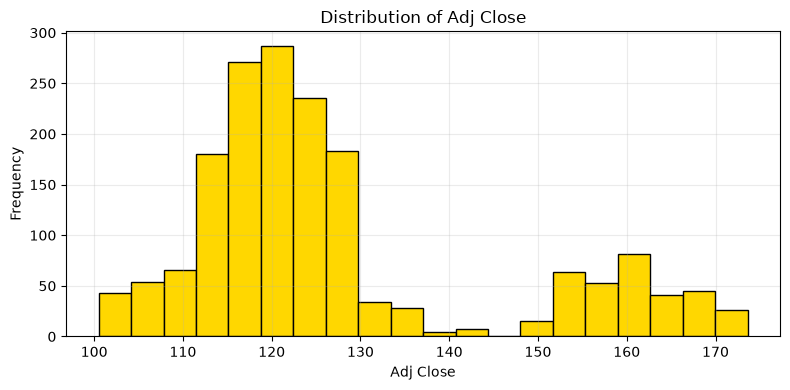

Saved outputs/gold_price_distribution.png


In [3]:
# Histogram of target Gold price (Adj Close)
column_to_plot = "Adj Close"
plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot].dropna(), bins=20, color="gold", edgecolor="black")
plt.title(f"Distribution of {column_to_plot}")
plt.xlabel(column_to_plot)
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("../outputs/gold_price_distribution.png")
plt.show()
print("Saved outputs/gold_price_distribution.png")

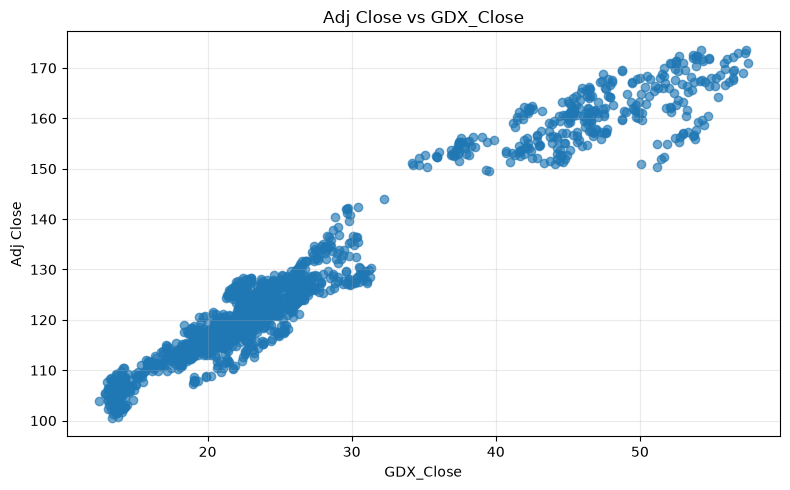

Saved outputs/feature_vs_gold_scatter.png


In [4]:
# Scatter plot: GDX_Close vs Adj Close
feature_for_plot = "GDX_Close"
target_for_plot = "Adj Close"
plt.figure(figsize=(8, 5))
plt.scatter(df[feature_for_plot], df[target_for_plot], alpha=0.65)
plt.title(f"{target_for_plot} vs {feature_for_plot}")
plt.xlabel(feature_for_plot)
plt.ylabel(target_for_plot)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("../outputs/feature_vs_gold_scatter.png")
plt.show()
print("Saved outputs/feature_vs_gold_scatter.png")

### **4. Preprocess the Data**

In [5]:
df = df.drop_duplicates().copy()

target_column = "Adj Close"
gld_columns = ["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"]
feature_columns = [col for col in df.columns if col not in gld_columns]

model_df = df[feature_columns + [target_column]].copy()
model_df[target_column] = pd.to_numeric(model_df[target_column], errors="coerce")
model_df = model_df.dropna(subset=[target_column])

X = model_df[feature_columns]
y = model_df[target_column]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Rows available for modelling:", len(model_df))

Input shape: (1718, 74)
Target shape: (1718,)
Rows available for modelling: 1718


### **5. Split into Training and Testing Data**

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 1374
Testing examples: 344


### **6. Building and Training the Linear Regression Model**

In [7]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)
print("Model training completed!")

Model training completed!


### **7. Make Predictions**

In [8]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred,
    "Error (Actual - Predicted)": y_test.to_numpy() - y_pred
})
comparison.head(10)

,Actual Price,Predicted Price,Error (Actual - Predicted)
0,127.699997,127.073399,0.626598
1,116.470001,116.476210,-0.006209
2,157.320007,153.748801,3.571206
3,155.089996,145.259841,9.830155
4,131.070007,132.098624,-1.028617
5,115.050003,112.680296,2.369707
6,127.489998,123.346812,4.143186
7,165.160004,169.446629,-4.286625
8,119.510002,114.417350,5.092652
9,107.839996,107.044893,0.795103


### **8. Evaluate the Model**

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.3f}")
print(f"MSE  : {mse:,.3f}")
print(f"RMSE : {rmse:,.3f}")
print(f"R²   : {r2:.3f}")

MAE  : 3.736
MSE  : 21.663
RMSE : 4.654
R²   : 0.930


### **9. Visualize Actual vs Predicted Prices**

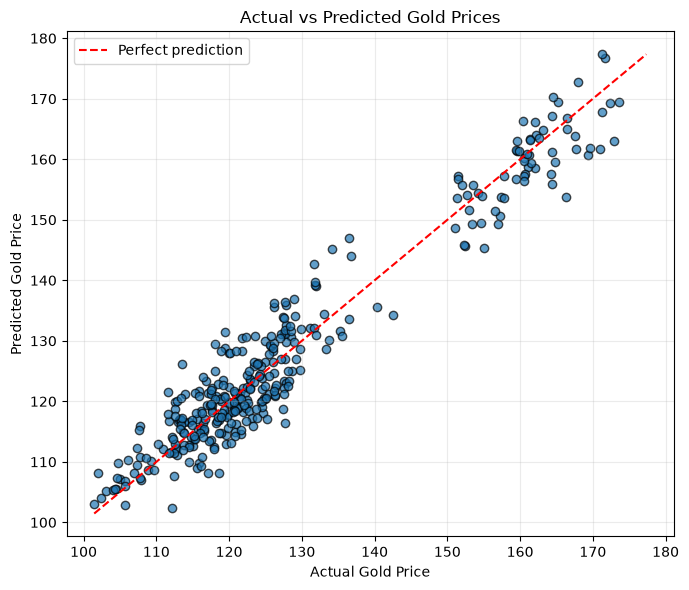

Saved outputs/predicted_vs_actual.png


In [15]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor="black")

low = min(float(np.min(y_test)), float(np.min(y_pred)))
high = max(float(np.max(y_test)), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--", color="red", label="Perfect prediction")

plt.xlabel("Actual Gold Price")
plt.ylabel("Predicted Gold Price")
plt.title("Actual vs Predicted Gold Prices")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("../outputs/predicted_vs_actual.png")
plt.show()
print("Saved outputs/predicted_vs_actual.png")

### **10. Correlation and Heatmap**

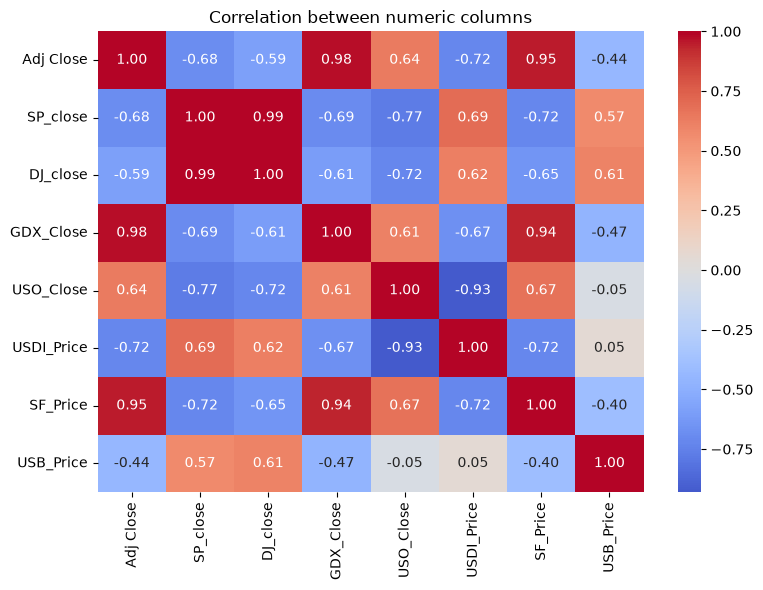

Saved outputs/correlation_heatmap.png
Correlation with Adj Close:
GDX_Close     0.98
SF_Price      0.95
USO_Close     0.64
USB_Price    -0.44
DJ_close     -0.59
SP_close     -0.68
USDI_Price   -0.72
Name: Adj Close, dtype: float64


In [17]:
number_cols = ["Adj Close", "SP_close", "DJ_close", "GDX_Close", "USO_Close", "USDI_Price", "SF_Price", "USB_Price"]
corr = df[number_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.savefig("../outputs/correlation_heatmap.png")
plt.show()
print("Saved outputs/correlation_heatmap.png")

print("Correlation with Adj Close:")
print(corr["Adj Close"].drop("Adj Close").sort_values(ascending=False).round(2))